# NLP Laboratory Assignment 04
## Country Prediction using Word Embeddings

| Field | Value |
|---|---|
| Student Name | **Shravani Balasaheb Kurkute** |
| Roll No. | 421129 |
| PRN / Registration No. | 22311926 |
| Class / Division | BTechA |
| Academic Year | 2026-2027 |
| Faculty Name | Dr. Kapil N. Vhatkar |

**Aim:** To understand semantic relationships represented by word embeddings
and use vector arithmetic and similarity measures to predict a country from a
capital-city relationship.

This notebook reproduces the complete experiment: it loads pre-trained GloVe
vectors, builds the analogue vector, predicts countries, evaluates the system
and analyses the errors. All numbers below are produced by executing this
notebook, not copied from a report.

## 1. Problem statement

Given three words `Capital 1`, `Country 1` and `Capital 2`, predict `Country 2`
using the analogy

`Athens : Greece :: Baghdad : ?  ->  Iraq`

The required vector operation is

$$\vec{v}_{query} = \vec{v}(Country_1) - \vec{v}(Capital_1) + \vec{v}(Capital_2)$$

Candidates are ranked by **cosine similarity** between the L2-normalised query
vector and the L2-normalised candidate vectors. Input words are excluded from
the ranking.

In [1]:
from pathlib import Path
import json
import platform
import sys

import numpy as np
import pandas as pd
import gensim
import gensim.downloader as api
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from country_prediction import (
    CountryAnalogyPredictor,
    evaluate_predictions,
    load_candidate_countries,
    load_embeddings,
    load_records,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

print("Python      :", platform.python_version())
print("gensim      :", gensim.__version__)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("project dir :", BASE_DIR)

Python      : 3.13.9
gensim      : 4.4.0
numpy       : 2.2.0
pandas      : 2.2.3
project dir : /home/shravanikurkute/BTech/4th Year/NLP/Assignment 4


## 2. Pre-trained embedding model

`glove-wiki-gigaword-100` (Pennington et al., 2014) is loaded through the
gensim downloader. The model has 400,000 lower-cased words of dimension 100 and
is cached in `~/gensim-data`, so it is only downloaded once.

In [2]:
vectors, model_info = load_embeddings()
model_info

[model] Loading word embeddings ...


[model] Source: gensim-data cache (~/gensim-data, 128 MB download on first use)


[model] glove-wiki-gigaword-100: 400,000 words, 100 dimensions, loaded in 21.2s


{'name': 'glove-wiki-gigaword-100',
 'source': 'gensim-data cache (~/gensim-data, 128 MB download on first use)',
 'vocabulary_size': 400000,
 'dimension': 100,
 'load_seconds': 21.18}

## 3. Datasets

`BuildDatasets.py` validated the curated capital-country list against the model
vocabulary and generated four CSV files plus metadata. Let us inspect them.

In [3]:
metadata = json.loads(Path("datasets/dataset_metadata.json").read_text())
metadata

{'source_pairs': 78,
 'valid_pairs': 78,
 'candidate_countries': 131,
 'skipped_pairs': [],
 'additional_countries_out_of_vocabulary': [],
 'test_size': 15,
 'large_size': 1000,
 'test_seed': 42,
 'large_seed': 2026,
 'embedding_vocabulary': 400000,
 'embedding_dimension': 100}

In [4]:
pairs = pd.read_csv("datasets/capitals_countries.csv")
candidates = pd.read_csv("datasets/candidate_countries.csv")
test_set = pd.read_csv("datasets/test_analogies.csv")
large_set = pd.read_csv("datasets/eval_analogies_large.csv")

print("capital-country pairs :", len(pairs))
print("candidate countries   :", len(candidates))
print("test analogies        :", len(test_set))
print("evaluation analogies  :", len(large_set))
pairs.head(8)

capital-country pairs : 78
candidate countries   : 131
test analogies        : 15
evaluation analogies  : 1000


,capital,country
0,athens,greece
1,baghdad,iraq
2,bangkok,thailand
3,beijing,china
4,berlin,germany
5,bern,switzerland
6,cairo,egypt
7,canberra,australia


In [5]:
test_set

,capital1,country1,capital2,country2
0,athens,greece,baghdad,iraq
1,kabul,afghanistan,beijing,china
2,beirut,lebanon,budapest,hungary
3,vienna,austria,madrid,spain
4,jakarta,indonesia,bratislava,slovakia
5,helsinki,finland,vientiane,laos
6,kathmandu,nepal,berlin,germany
7,beijing,china,helsinki,finland
8,tokyo,japan,warsaw,poland
9,sofia,bulgaria,london,england


In [6]:
large_set.head(8)

,capital1,country1,capital2,country2
0,lima,peru,caracas,venezuela
1,sofia,bulgaria,bucharest,romania
2,jakarta,indonesia,vienna,austria
3,delhi,india,valletta,malta
4,mogadishu,somalia,doha,qatar
5,reykjavik,iceland,riga,latvia
6,vientiane,laos,tashkent,uzbekistan
7,havana,cuba,athens,greece


## 4. The required example, step by step

We take the normalised vectors of **Greece**, **Athens** and **Baghdad**, build
the query vector, and score it against **Iraq** and other countries.

In [7]:
capital1, country1, capital2 = "athens", "greece", "baghdad"
query = (
    vectors[country1]
    - vectors[capital1]
    + vectors[capital2]
)
query_unit = query / np.linalg.norm(query)

for word in ("iraq", "afghanistan", "lebanon", "syria", "greece"):
    unit = vectors[word] / np.linalg.norm(vectors[word])
    print(f"cosine(query, {word:<12}) = {float(query_unit @ unit):.4f}")

cosine(query, iraq        ) = 0.8050
cosine(query, afghanistan ) = 0.7204
cosine(query, lebanon     ) = 0.6908
cosine(query, syria       ) = 0.6641
cosine(query, greece      ) = 0.3833


In [8]:
predictor = CountryAnalogyPredictor(vectors, load_candidate_countries())
predictor.model_info = model_info

filtered = predictor.rank(capital1, country1, capital2, topn=5)
full_vocab = predictor.rank(capital1, country1, capital2, topn=5, country_filter=False)

print("country-filtered:", ", ".join(f"{w} ({s:.3f})" for w, s in filtered))
print("full vocabulary :", ", ".join(f"{w} ({s:.3f})" for w, s in full_vocab))
print("\nPredicted Country 2 =", filtered[0][0].upper())

country-filtered: iraq (0.790), afghanistan (0.708), lebanon (0.678), syria (0.655), kuwait (0.622)
full vocabulary : iraq (0.790), afghanistan (0.708), lebanon (0.678), arabia (0.666), syria (0.655)

Predicted Country 2 = IRAQ


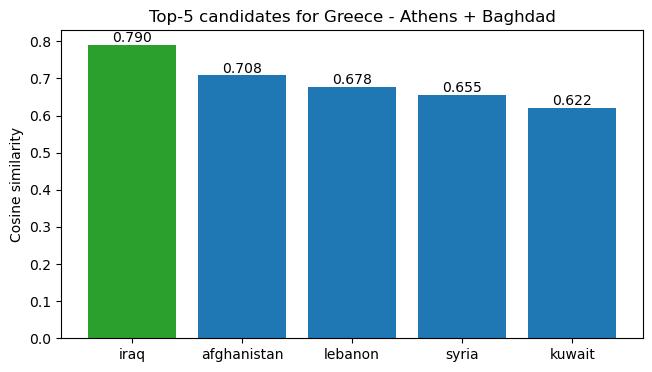

In [9]:
labels = [word for word, _ in filtered]
scores = [score for _, score in filtered]
colors = ["#2ca02c" if word == "iraq" else "#1f77b4" for word in labels]

fig, axis = plt.subplots(figsize=(7.5, 4))
axis.bar(labels, scores, color=colors)
axis.set_ylabel("Cosine similarity")
axis.set_title("Top-5 candidates for Greece - Athens + Baghdad")
for index, score in enumerate(scores):
    axis.annotate(f"{score:.3f}", (index, score), ha="center", va="bottom")
plt.show()

## 5. Evaluation on the 15-example test set

The test set contains the required example plus 14 randomly sampled analogies
(fixed seed 42). We compare **country-filtered** search with **full-vocabulary**
search.

In [10]:
test_records = load_records("datasets/test_analogies.csv")
rows_filtered, metrics_filtered = evaluate_predictions(
    predictor, test_records, country_filter=True
)
rows_full, metrics_full = evaluate_predictions(
    predictor, test_records, country_filter=False
)

test_table = pd.DataFrame(
    {
        "analogy": [
            f"{r['capital1'].title()} : {r['country1'].title()} :: "
            f"{r['capital2'].title()} : ?"
            for r in rows_filtered
        ],
        "actual": [r["actual_country2"] for r in rows_filtered],
        "predicted": [r["predicted_country"] for r in rows_filtered],
        "score": [round(r["predicted_score"], 3) for r in rows_filtered],
        "margin": [round(r["margin"], 3) for r in rows_filtered],
        "result": ["Correct" if r["correct"] else "Incorrect" for r in rows_filtered],
    }
)
test_table

,analogy,actual,predicted,score,margin,result
0,Athens : Greece :: Baghdad : ?,iraq,iraq,0.790,0.082,Correct
1,Kabul : Afghanistan :: Beijing : ?,china,china,0.843,0.151,Correct
2,Beirut : Lebanon :: Budapest : ?,hungary,hungary,0.795,0.086,Correct
3,Vienna : Austria :: Madrid : ?,spain,spain,0.769,0.110,Correct
4,Jakarta : Indonesia :: Bratislava : ?,slovakia,slovakia,0.811,0.105,Correct
5,Helsinki : Finland :: Vientiane : ?,laos,laos,0.660,0.127,Correct
6,Kathmandu : Nepal :: Berlin : ?,germany,germany,0.816,0.136,Correct
7,Beijing : China :: Helsinki : ?,finland,finland,0.693,0.076,Correct
8,Tokyo : Japan :: Warsaw : ?,poland,poland,0.845,0.134,Correct
9,Sofia : Bulgaria :: London : ?,england,england,0.690,0.019,Correct


In [11]:
pd.DataFrame(
    {
        "test-15": [metrics_filtered["top1_accuracy_pct"], metrics_filtered["top5_accuracy_pct"]],
        "test-15 full vocab": [metrics_full["top1_accuracy_pct"], metrics_full["top5_accuracy_pct"]],
    },
    index=["top-1 accuracy %", "top-5 accuracy %"],
)

,test-15,test-15 full vocab
top-1 accuracy %,93.33,86.67
top-5 accuracy %,100.00,100.00


## 6. Evaluation on 1,000 generated analogies

`eval_analogies_large.csv` contains 1,000 unique analogies generated with seed
2026. Both search modes are evaluated.

In [12]:
large_records = load_records("datasets/eval_analogies_large.csv")
large_filtered, metrics_large_filtered = evaluate_predictions(
    predictor, large_records, country_filter=True
)
large_full, metrics_large_full = evaluate_predictions(
    predictor, large_records, country_filter=False
)

summary = pd.DataFrame(
    [
        {"dataset": "test-15", "mode": "country-filtered", **{
            k: metrics_filtered[k] for k in
            ("total", "correct_top1", "incorrect_top1", "top1_accuracy_pct",
             "top5_accuracy_pct", "mean_top1_margin")
        }},
        {"dataset": "test-15", "mode": "full vocabulary", **{
            k: metrics_full[k] for k in
            ("total", "correct_top1", "incorrect_top1", "top1_accuracy_pct",
             "top5_accuracy_pct", "mean_top1_margin")
        }},
        {"dataset": "1,000", "mode": "country-filtered", **{
            k: metrics_large_filtered[k] for k in
            ("total", "correct_top1", "incorrect_top1", "top1_accuracy_pct",
             "top5_accuracy_pct", "mean_top1_margin")
        }},
        {"dataset": "1,000", "mode": "full vocabulary", **{
            k: metrics_large_full[k] for k in
            ("total", "correct_top1", "incorrect_top1", "top1_accuracy_pct",
             "top5_accuracy_pct", "mean_top1_margin")
        }},
    ]
)
summary

[ranking] 1000/1000 analogies

[ranking] 1000/1000 analogies

,dataset,mode,total,correct_top1,incorrect_top1,top1_accuracy_pct,top5_accuracy_pct,mean_top1_margin
0,test-15,country-filtered,15,14,1,93.33,100.0,0.1054
1,test-15,full vocabulary,15,13,2,86.67,100.0,0.0941
2,"1,000",country-filtered,1000,944,56,94.40,98.9,0.0978
3,"1,000",full vocabulary,1000,922,78,92.20,97.7,0.0880


## 7. Saved visualizations

These charts were produced from the saved result files by
`tools/generate_visualizations.py`.

accuracy_comparison.png


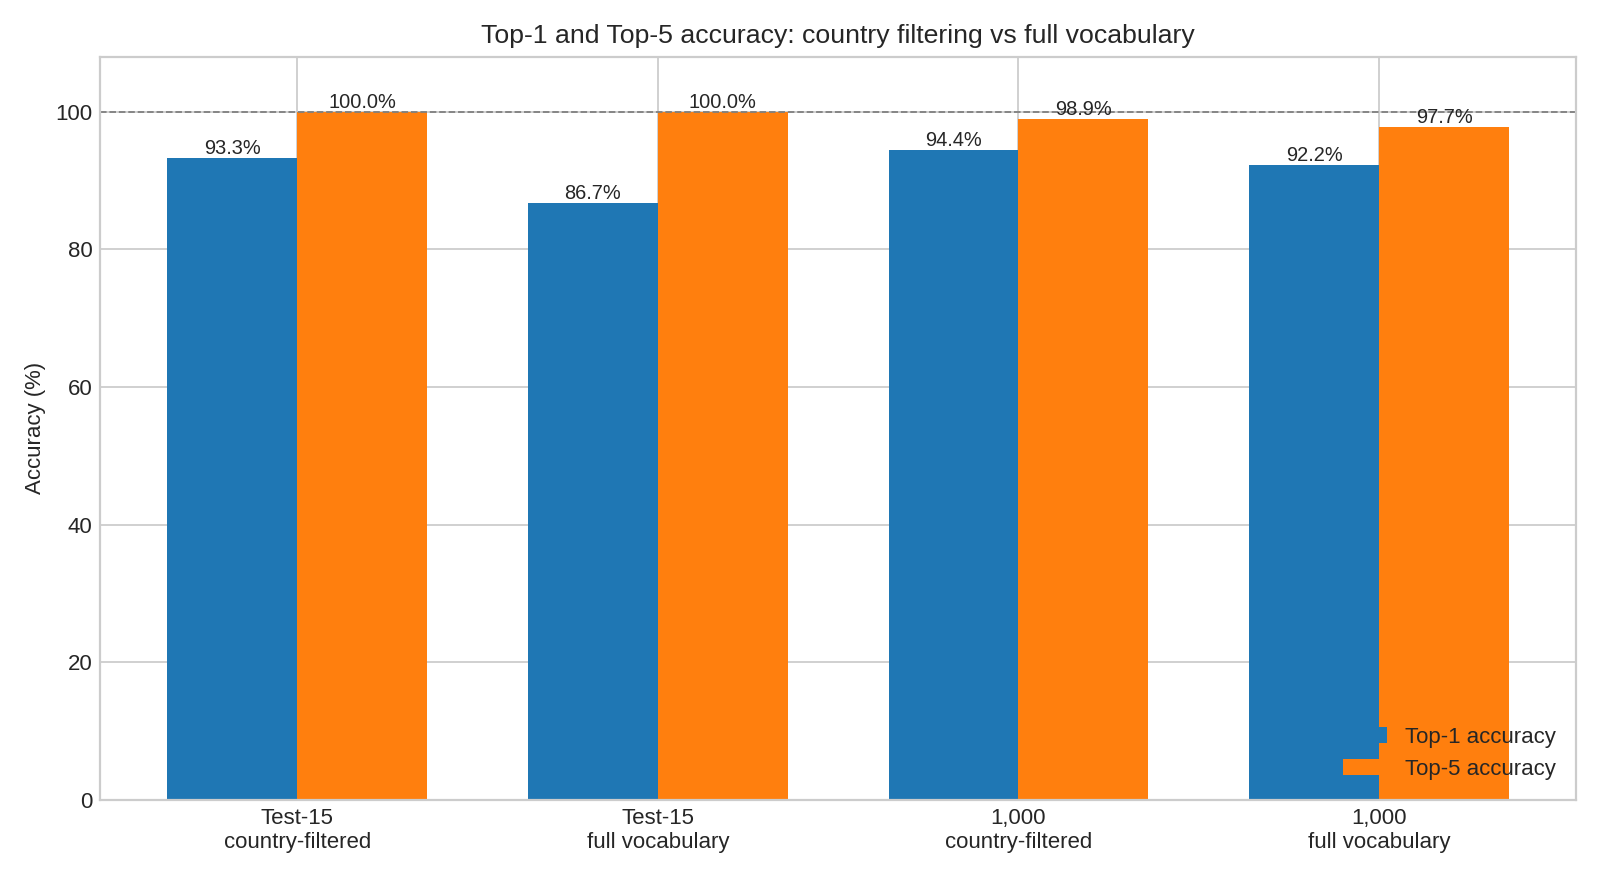

similarity_distribution.png


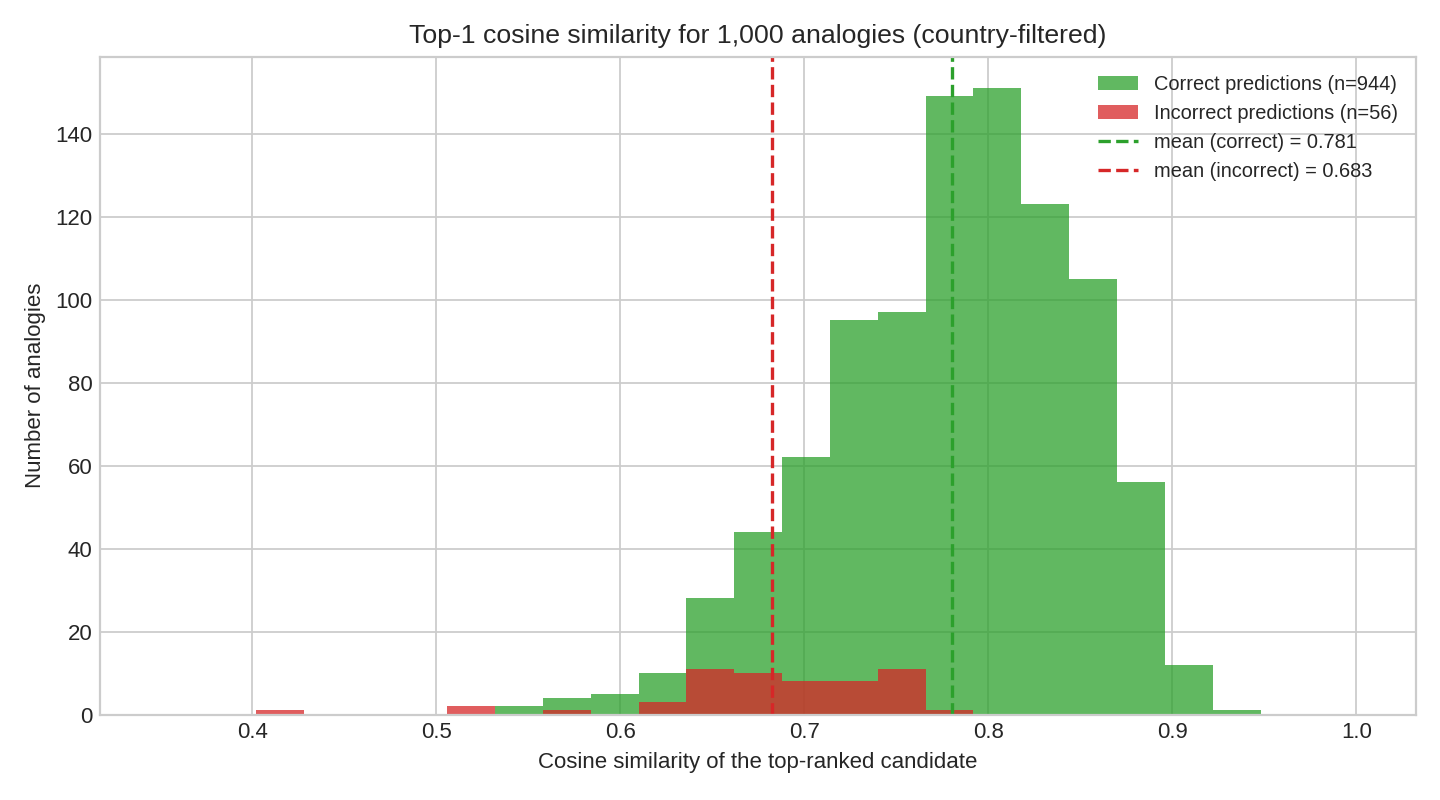

errors_by_country.png


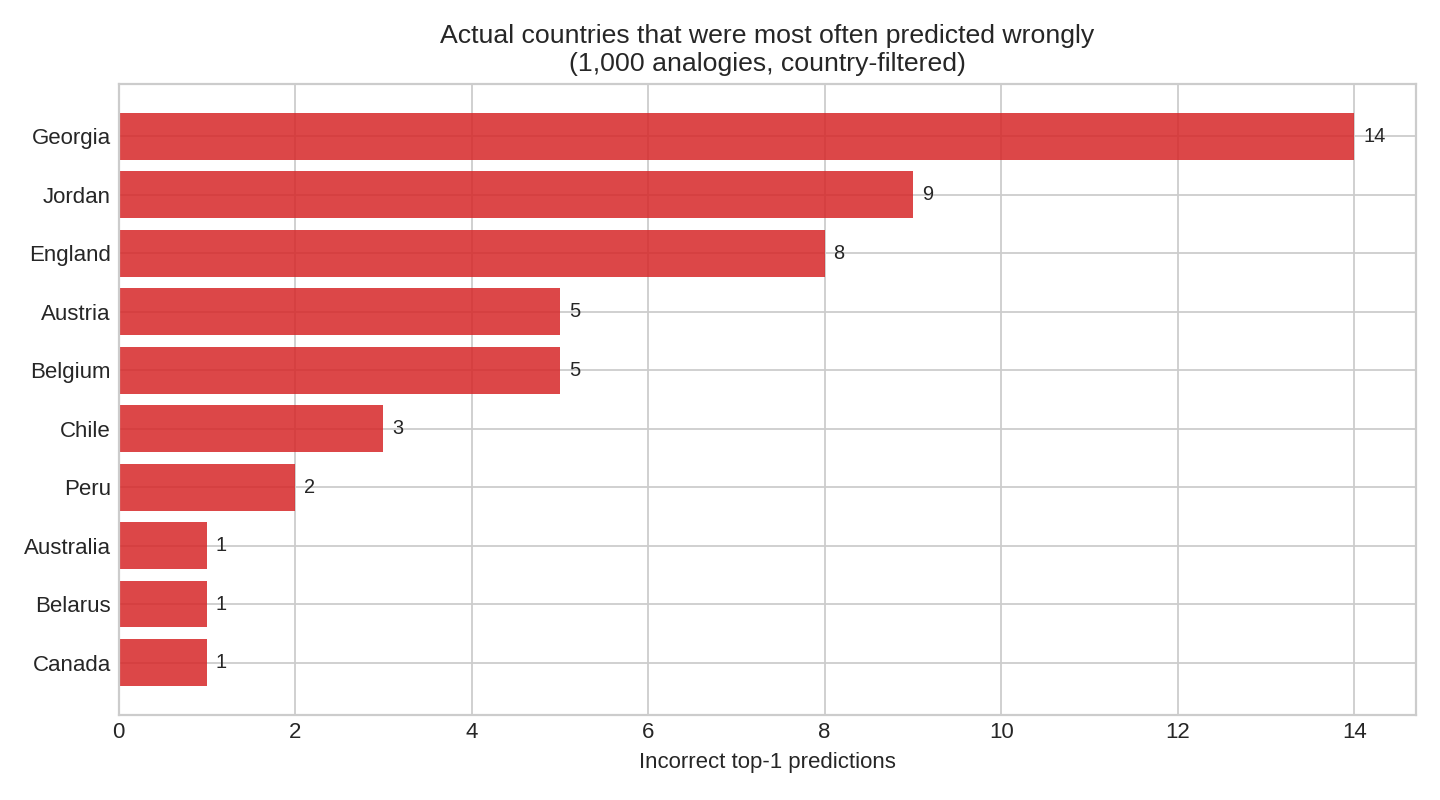

rank_distribution.png


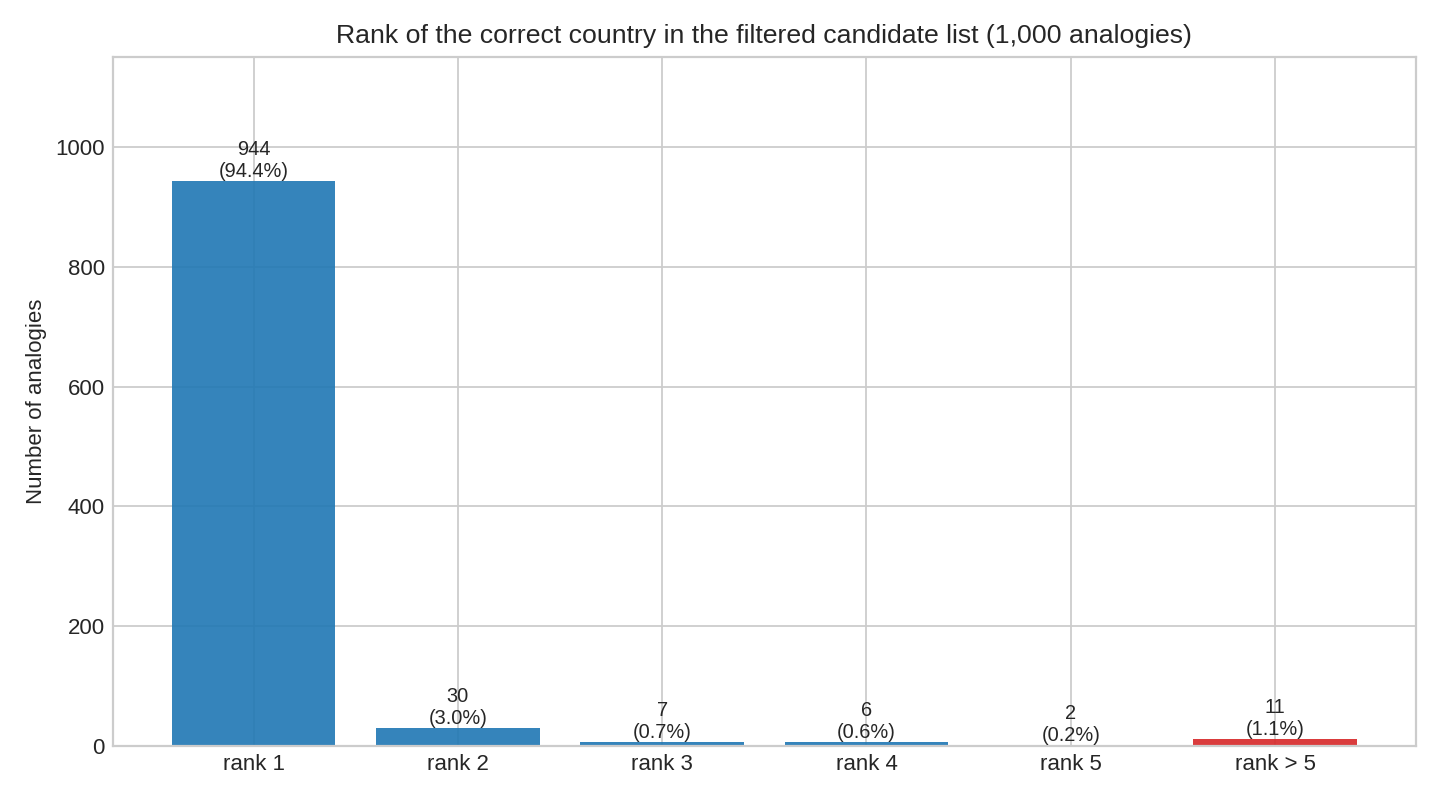

test15_confidence.png


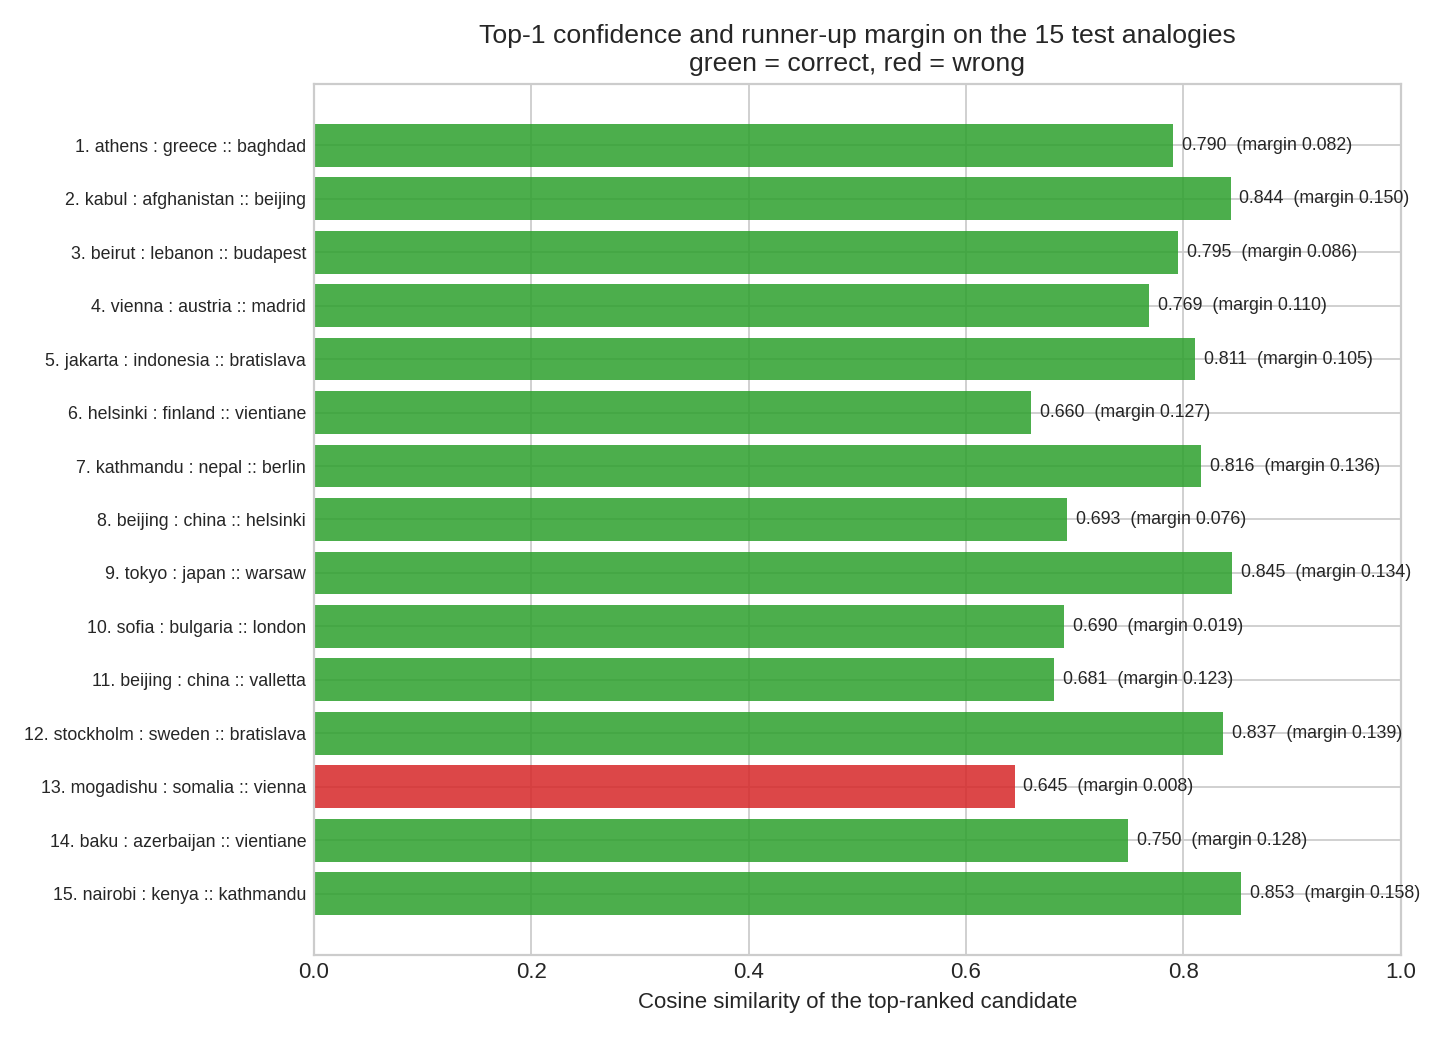

analogy_vector_pca.png


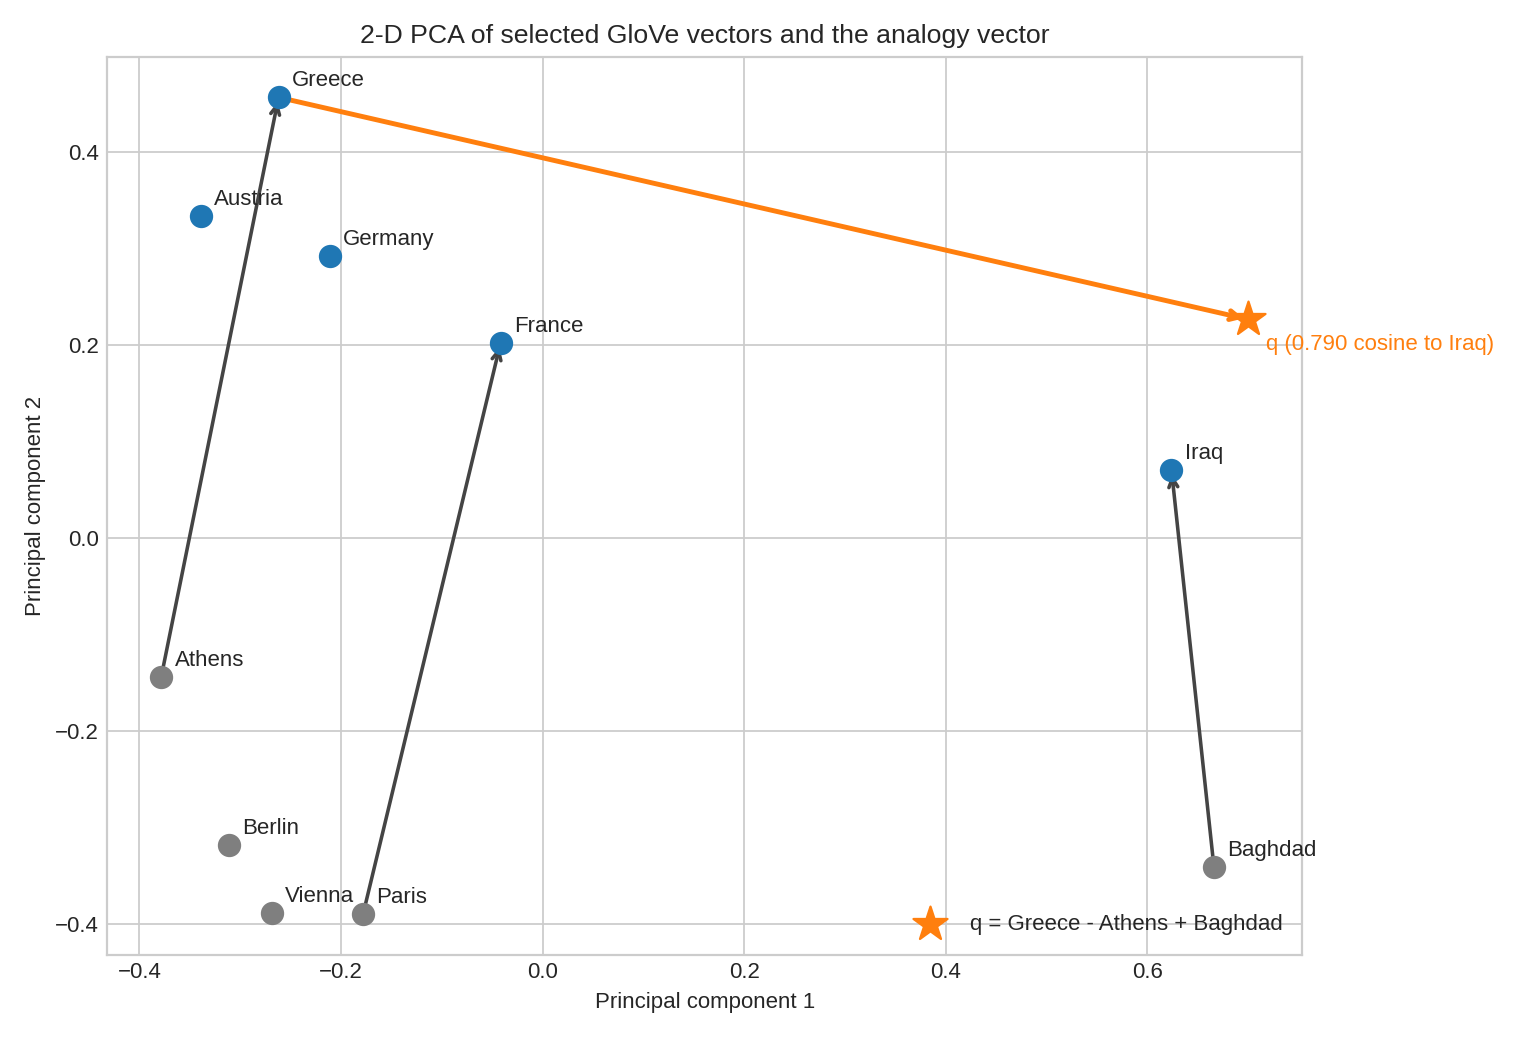

In [13]:
from IPython.display import Image, display

for name in (
    "accuracy_comparison.png",
    "similarity_distribution.png",
    "errors_by_country.png",
    "rank_distribution.png",
    "test15_confidence.png",
    "analogy_vector_pca.png",
):
    print(name)
    display(Image(filename=f"visualizations/{name}", width=760))

## 8. Error analysis

`error_analysis_*.csv` files list every incorrect prediction with the input
analogy, the actual and predicted country, both similarity scores, the rank of
the correct country and a short explanation.

In [14]:
test_errors = pd.read_csv("results/error_analysis_test15_country_filtered.csv")
test_errors[["capital1", "country1", "capital2", "actual_country2",
             "predicted_country", "predicted_score", "actual_score",
             "actual_rank", "error_category"]]

,capital1,country1,capital2,actual_country2,predicted_country,predicted_score,actual_score,actual_rank,error_category
0,mogadishu,somalia,vienna,austria,germany,0.6447,0.6368,2,neighbouring / culturally close country


In [15]:
large_errors = pd.read_csv("results/error_analysis_large1000_country_filtered.csv")
print("incorrect predictions:", len(large_errors))
display(large_errors[["country1", "capital2", "actual_country2",
                      "predicted_country", "actual_rank", "error_category"]].head(12))
large_errors["error_category"].value_counts()

incorrect predictions: 56


,country1,capital2,actual_country2,predicted_country,actual_rank,error_category
0,qatar,bogota,colombia,venezuela,2,neighbouring / culturally close country
1,india,tbilisi,georgia,armenia,7,ambiguous word
2,oman,bratislava,slovakia,latvia,2,close competition
3,finland,tbilisi,georgia,armenia,4,ambiguous word
4,venezuela,london,england,australia,2,ambiguous word
5,somalia,vienna,austria,germany,2,neighbouring / culturally close country
6,australia,vienna,austria,germany,3,neighbouring / culturally close country
7,algeria,tbilisi,georgia,azerbaijan,12,ambiguous word
8,spain,abuja,nigeria,malawi,2,close competition
9,georgia,muscat,oman,jordan,2,close competition


error_category
ambiguous word                             35
neighbouring / culturally close country    13
close competition                           8
Name: count, dtype: int64

In [16]:
breakdown = (
    large_errors.groupby("actual_country2").size()
    .sort_values(ascending=False)
    .head(10)
    .rename("errors")
)
breakdown

actual_country2
georgia      14
jordan        9
england       8
belgium       5
austria       5
chile         3
peru          2
australia     1
canada        1
cyprus        1
Name: errors, dtype: int64

## 9. Observations

1. The required example is solved: `athens : greece :: baghdad` gives **iraq**
   as the top candidate with a cosine similarity of about 0.79.
2. On the 15-example test set the country-filtered system gets the top-1
   country right for 14 of 15 analogies (93.33%). The only error is
   `Mogadishu : Somalia :: Vienna : ?`, where **germany** (0.645) edges out
   **austria** (0.637); the correct country is still ranked 2nd.
3. Searching the full 400k-word vocabulary lowers test accuracy to 13/15
   (86.67%): for `London`, **britain** (0.795) is ranked above **england**
   (0.690). Country filtering therefore removes spurious non-country neighbours.
4. On the 1,000 generated analogies the country-filtered system reaches
   94.40% top-1 and 98.90% top-5 accuracy; with the full vocabulary it reaches
   92.20% top-1 and 97.70% top-5. Filtering adds 2.20 and 1.20 percentage
   points respectively.
5. Most correct top-1 similarities lie between 0.65 and 0.85. The mean top-1
   margin is small (about 0.10 on the large set), which explains why a few
   neighbouring countries are confused.
6. Mistakes concentrate on ambiguous names (Georgia, Jordan, England, Chile)
   and closely related neighbours (Austria/Germany, Belgium/France).

## 10. Limitations

- Static embeddings give one vector per word, so polysemous names (Georgia the
  country vs. the US state, Jordan the name, Turkey the bird) are conflated.
- Only single-word names are supported; multi-word names such as *Saudi Arabia*
  or *New Delhi* are outside the model vocabulary.
- The evaluation analogies are recombinations of the same 78 capital-country
  pairs, so they are not independent test items.
- A single linear offset cannot represent every capital-country relationship,
  especially for rare capitals whose vectors were seen infrequently during
  GloVe training.
- Results depend on the 2014 Wikipedia + Gigaword corpus and cannot reflect
  later geopolitical changes.

## 11. Conclusion

Pre-trained GloVe embeddings capture the capital-country relationship well
enough to solve analogies by vector arithmetic. Restricting the search to a
curated country list and excluding the input words improve accuracy. The
remaining errors are dominated by ambiguous words and geographically or
culturally close countries, which is the expected behaviour of static
embeddings.

## 12. References

1. Pennington, J., Socher, R., & Manning, C. D. (2014). *GloVe: Global Vectors
   for Word Representation.* EMNLP 2014, 1532-1543.
2. Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). *Efficient Estimation
   of Word Representations in Vector Space.* arXiv:1301.3781.
3. Mikolov, T., Yih, W., & Zweig, G. (2013). *Linguistic Regularities in
   Continuous Space Word Representations.* NAACL-HLT 2013, 746-751.
4. Rehurek, R., & Sojka, P. (2010). *Software Framework for Topic Modelling
   with Large Corpora.* LREC 2010 Workshop, 45-50 (gensim).
5. Jurafsky, D., & Martin, J. H. *Speech and Language Processing* (3rd ed.
   draft), Chapter 6: Vector Semantics and Embeddings.